In [55]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time

from sunpy.net import Fido, attrs as a
from sunpy.coordinates import HeliographicStonyhurst

In [52]:
filename = "EVE_L4_0_2010125_00.fit"

with fits.open(filename) as hdul:
    

    hdu = hdul["Spectrum"]
    print(f"\n{"Spectrum"}")
    print(hdu.columns.names)
    if hdu.data is not None:
       print(hdu.data[0])


Spectrum
['SOD', 'WAVELENGTH', 'SPECTRA']
(array([3.000e+01, 9.000e+01, 1.500e+02, ..., 8.625e+04, 8.631e+04,
       8.637e+04], shape=(1440,), dtype='>f4'), array([1.0000e-02, 3.0000e-02, 5.0000e-02, ..., 1.0595e+02, 1.0597e+02,
       1.0599e+02], shape=(5300,), dtype='>f8'), array([[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [4.6910741e-06, 4.6912269e-06, 4.6915461e-06, ..., 4.7325611e-06,
        4.7326030e-06, 4.7323101e-06],
       [4.6090704e-06, 4.6092309e-06, 4.6095656e-06, ..., 4.6525975e-06,
        4.6526416e-06, 4.6523342e-06],
       [4.3167643e-06, 4.3169339e-06, 4.3172868e-06, ..., 4.3626856e-06,
        4.3627319e-06, 4.3624077e-06]], shape=(5300, 1440), dtype='>f4'))


In [26]:

filename = "Solar_Flare_Project/FITS/EVE_LINESFIT_L4_2010125_008_01.fit"


with fits.open(filename) as hdul:
    for name in ["LinesMeta", "LinesFitParams", "LinesFitAccuracy",
                 "LinesData", "FlareFitParams"]:
        hdu = hdul[name]
        print(f"\n{name}")
        print(hdu.columns.names)
        if hdu.data is not None:
            print(hdu.data[0])

KeyError: "Extension 'LinesMeta' not found."

In [23]:
result = Fido.search(
        a.Time("2010-05-05 00:00:00", "2010-05-05 01:00:00"),
        a.Instrument("EVE"),
        a.Level(4)
    )
result

Start Time,End Time,Source,Instrument,Provider,Physobs,Extent Type,Size
,,,,,,,Mibyte
Time,Time,str3,str3,str4,str10,str8,float64
2010-05-05 00:00:00.000,2010-05-06 00:00:00.000,SDO,EVE,LASP,irradiance,FULLDISK,-0.00098
2010-05-05 00:00:00.000,2010-05-06 00:00:00.000,SDO,EVE,LASP,irradiance,FULLDISK,-0.00098


In [24]:
Fido.fetch(result)

Files Downloaded:   0%|                                                                        | 0/2 [00:00<?, ?file/s]

EVE_L4_LINESFIT_2010125_00:   0%|                                                          | 0.00/12.8M [00:00<?, ?B/s]
EVE_L4_0_2010125_00:   0%|                                                                 | 0.00/30.6M [00:00<?, ?B/s]

EVE_L4_LINESFIT_2010125_00:   0%|                                                 | 1.02k/12.8M [00:00<34:42, 6.15kB/s]
EVE_L4_0_2010125_00:   0%|                                                      | 1.02k/30.6M [00:00<1:24:50, 6.01kB/s]

EVE_L4_LINESFIT_2010125_00:   0%|                                                 | 16.7k/12.8M [00:00<03:11, 66.8kB/s]
EVE_L4_0_2010125_00:   0%|                                                        | 18.1k/30.6M [00:00<07:12, 70.7kB/s]

EVE_L4_LINESFIT_2010125_00:   0%|▏                                                 | 40.3k/12.8M [00:00<01:52, 113kB/s]
EVE_L4_0_2010125_00:   0%|          

['/Users/scottd/sunpy/data/EVE_L4_0_2010125_00', '/Users/scottd/sunpy/data/EVE_L4_LINESFIT_2010125_00']

In [13]:
with fits.open(filename) as hdul:
    lines_meta = hdul["LinesMeta"].data
    lines_data = hdul["LinesData"].data

    print("Metadata columns:", hdul["LinesMeta"].columns.names)
    print("Data columns:", hdul["LinesData"].columns.names)
    print("Data columns:", hdul["LinesFitParams"].columns.names)
    print("Data columns:", hdul["LinesFitAccuracy"].columns.names)
    print("Data columns:", hdul["FlareFitParams"].columns.names)

Metadata columns: ['LINE_WAVELENGTH', 'LINE_TEMP_MK', 'LINE_TEMP_MIN', 'LINE_TEMP_MAX', 'BLEND_ERROR', 'LINE_ELEMENTS', 'LINE_IONS']
Data columns: ['TAI', 'YYYYDOY', 'SOD', 'FLAGS', 'SC_FLAGS', 'LINE_IRRADIANCE']
Data columns: ['WAVELENGTH', 'AMPLITUDE', 'GAUSS_WIDTH', 'BACKGROUND', 'FIT_CHI2', 'ERR_WAVELENGTH', 'ERR_AMPLITUDE', 'ERR_GAUSS_WIDTH', 'ERR_BACKGROUND', 'LEFT_WAVELENGTH', 'LEFT_AMPLITUDE', 'LEFT_GAUSS_WIDTH', 'ERR_LEFT_AMPLITUDE', 'RIGHT_WAVELENGTH', 'RIGHT_AMPLITUDE', 'RIGHT_GAUSS_WIDTH', 'ERR_RIGHT_AMPLITUDE', 'FIT_VALID']
Data columns: ['FIT_ACCURACY']
Data columns: ['GOES_XRSA', 'GOES_XRSB', 'GOES_TEMP_MK', 'FLARE_FLAG', 'PREFLARE_TIME_JD', 'FLARE_IRRADIANCE', 'FLARE_WAVELENGTH', 'FLARE_AMPLITUDE', 'FLARE_BACKGROUND', 'FLARE_FIT_CHI2', 'ERR_WAVELENGTH', 'ERR_AMPLITUDE', 'ERR_BACKGROUND', 'FIT_VALID']


In [54]:
l4_lines_file = filename
line_index = 65

with fits.open(l4_lines_file) as hdu_list:
    # extract data
    linesmeta = hdu_list["LINESMETA"].data
    linesfitparams = hdu_list["LINESFITPARAMS"].data
    linesdata = hdu_list["LINESDATA"].data
    # FIT_VALID = 1 indicates good data
    fit_valid = linesfitparams["FIT_VALID"][:, line_index]
    good = np.where(fit_valid == 1)[0]
    # irradiance for selected line
    irradiance = linesdata["LINE_IRRADIANCE"][0][good, line_index]
    # convert TAI seconds to datetime
    tai_seconds = linesdata["TAI"].flatten()[good]
    epoch = np.datetime64("1958-01-01T00:00:00")
    times = epoch + tai_seconds.astype("timedelta64[s]")
    # plot title
    wavelength = linesmeta["LINE_WAVELENGTH"][line_index]
    ions = linesmeta["LINE_IONS"][line_index].strip()
    title = f"EVE L4 lines fit timeseries {wavelength:.1f} nm ({ions})"
    # plot
    plt.figure(figsize=(10, 6))
    plt.plot(times, irradiance, 'k-', linewidth=0.8)
    plt.autoscale(enable=True, axis='x', tight=True)
    plt.xlabel("Time (UTC)")
    plt.ylabel("Irradiance (W/m²/nm)")
    plt.title(title)
    plt.grid(True, color='lightgray', zorder=0)
    plt.tight_layout()
    plt.show()

KeyError: "Extension 'LINESMETA' not found."

In [31]:
from astropy.io import fits
from astropy.time import Time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

filename = "EVL_L2_2016002_00_008_01.fit.gz"

with fits.open(filename) as hdul:
    data = hdul["LinesData"].data
    meta = hdul["LinesMeta"].data

    tai = np.asarray(data["TAI"], dtype=float)
    line_irradiance = np.asarray(data["LINE_IRRADIANCE"])

    # Inspect the available emission lines
    for i, line in enumerate(meta):
        print(i, line["NAME"], line["WAVE_CENTER"])

# Select the first emission line
line_index = 0

# TAI is seconds in the TAI time system; convert to UTC.
# The reference epoch must be taken from the FITS product definition.

0 Fe XVIII 9.3926
1 Fe VIII 13.124
2 Fe XX 13.285
3 Fe IX 17.1073
4 Fe X 17.7243
5 Fe XI 18.0407
6 Fe XII 19.512
7 Fe XIII 20.2044
8 Fe XIV 21.1331
9 He II 25.6317
10 Fe XV 28.415
11 He II 30.3783
12 Fe XVI 33.541
13 Fe XVI 36.0758
14 Mg IX 36.8076
15 S XIV 44.57
16 Ne VII 46.5221
17 Si XII 49.9406
18 Si XII 52.1
19 O III 52.5795
20 He I 53.703
21 O IV 55.437
22 Al XI 56.813
23 He I 58.4334
24 Fe XIX 59.224
25 O III 59.9598
26 Mg X 60.98
27 Mg X 62.4943
28 O V 62.973
29 O II 71.8535
30 Fe XX 72.156
31 Ne VIII 77.0409
32 O IV 79.0199
33 O II 83.55
34 H I 94.97
35 H I 97.2537
36 C III 97.703
37 H I 102.572
38 O VI 103.19
39 Fe XVIII 10.3948
40 Fe XXII 11.723
41 Ni XI 14.8377
42 Fe X 17.4531
43 Fe XIII 20.3826
44 O V 21.5167
45 Fe IX 21.7101
46 Fe XIV 21.913
47 Fe XV 23.3866
48 O IV 23.857
49 Fe IX 24.1739
50 Ni XVIII 24.9189
51 Fe XIV 26.4788
52 Mg VI 27.039
53 Fe XX 38.4209
54 Ar XVI 38.9066
55 S XIV 41.766
56 Ne IV 46.985
57 O III 50.808
58 Fe XX 54.199
59 Ne IV 54.3886
60 Al XI 55.003

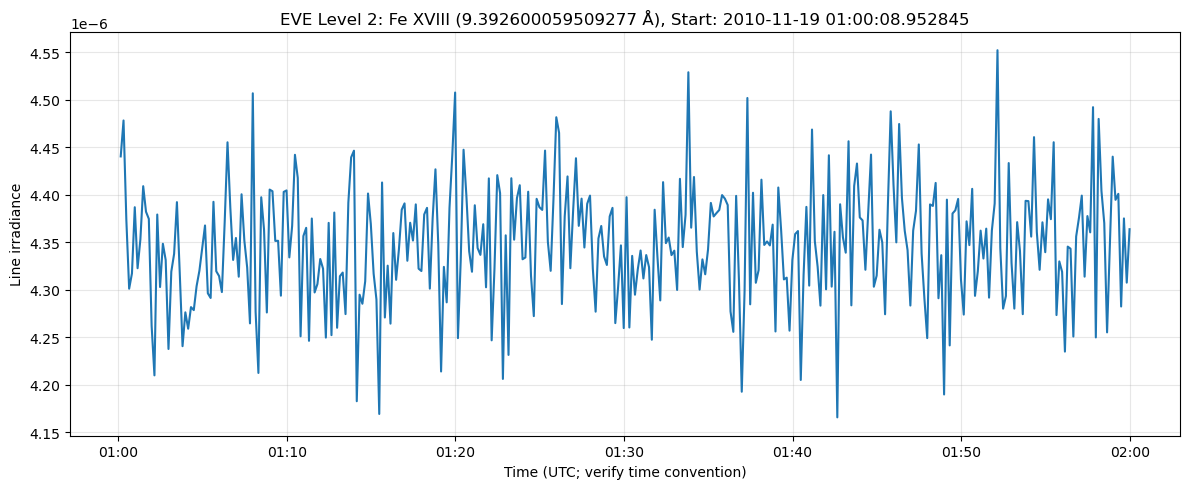

In [30]:
from astropy.io import fits
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

filename = "EVL_L2_2010323_01_008_01.fit.gz"

with fits.open(filename) as hdul:
    data = hdul["LinesData"].data
    meta = hdul["LinesMeta"].data

    line_irradiance = np.asarray(data["LINE_IRRADIANCE"])
    year_doy = data["YYYYDOY"]
    sod = data["SOD"]

# Convert YYYYDOY and SOD to datetime
times = []
for yd, seconds in zip(year_doy, sod):
    year = int(yd) // 1000
    doy = int(yd) % 1000
    dt = datetime(year, 1, 1) + timedelta(
        days=doy - 1, seconds=float(seconds)
    )
    times.append(dt)

# Choose an emission line
line_index = 0

plt.figure(figsize=(12, 5))
plt.plot(times, line_irradiance[:, line_index])
plt.xlabel("Time (UTC; verify time convention)")
plt.ylabel("Line irradiance")
plt.title(
    f"EVE Level 2: {meta[line_index]['NAME']} "
    f"({meta[line_index]['WAVE_CENTER']} Å)"
    f", Start: {times[0]}"
)
plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M")
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()